# Preamble

In [1]:
# Package imports
import sqlite3
import pandas as pd
import missingno as msno
import numpy as np
import datetime as dt

In [2]:
# Establish sqlite connection
conn = sqlite3.connect('data/revolut_home_task.db')

In [3]:
# Read data into Pandas dataframe
data = pd.read_excel(
    'data/Data Set - Home Task.xlsx',
    sheet_name='Data',
    dtype={
        'Unnamed: 0':'int64',
        'user_id':'string',
        'user_city':'string',
        'user_country':'string',
        'account_level_1':'string',
        'account_level_2':'string',
        'account_level_3':'string',
        'account_level_4':'string',
        'amount_gbp':'float64',
        'user_type':'string',
        'age_group':'string',
        'user_state':'string',
        'user_plan':'string',
        'is_nap':'string'
    },
    parse_dates=[
        'pnl_date',
        'onboarded_date',
        'pnl_month'
    ]
)

# Data quality Exploration

In [4]:
# Display column names, number of missing values and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196187 entries, 0 to 196186
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Unnamed: 0       196187 non-null  int64         
 1   user_id          196187 non-null  string        
 2   pnl_date         196187 non-null  datetime64[ns]
 3   user_city        188185 non-null  string        
 4   user_country     196187 non-null  string        
 5   account_level_1  196187 non-null  string        
 6   account_level_2  196187 non-null  string        
 7   account_level_3  196187 non-null  string        
 8   account_level_4  196187 non-null  string        
 9   amount_gbp       196187 non-null  float64       
 10  user_type        196187 non-null  string        
 11  age_group        192201 non-null  string        
 12  onboarded_date   192631 non-null  object        
 13  user_state       196187 non-null  string        
 14  user_plan        195

In [5]:
data.head()

,Unnamed: 0,user_id,pnl_date,user_city,user_country,account_level_1,account_level_2,account_level_3,account_level_4,amount_gbp,user_type,age_group,onboarded_date,user_state,user_plan,is_nap,pnl_month
0,0,e4457c08,2024-06-02,Banbridge,United Kingdom,Revolut Retail,Card Payments,ATM,Partner: Fire,-0.081655,PERSONAL,65-74,2018-03-22 09:11:32.417000+00:00,Active,PREMIUM,Napped,2024-06-01
1,1,c4373067,2024-07-11,<NA>,Ireland,Revolut Retail,Card Payments,Interchange Fees,Partner: Fire,0.065987,PERSONAL,35-44,2019-10-04 08:16:24.980661+00:00,Active,STANDARD,Napped,2024-07-01
2,2,f9e1ab71,2024-05-28,London,United Kingdom,Revolut Retail,Card Payments,Interchange Fees,Partner: Fire,0.001900,PERSONAL,35-44,2020-02-09 16:03:40.706014+00:00,Active,ULTRA,Napped,2024-05-01
3,3,8393cab9,2024-06-16,Zagreb,Croatia,Treasury,Interest Income,Cash at Banks,-,0.006827,PERSONAL,45-54,2020-05-23 12:02:31.406355+00:00,Active,STANDARD,Napped,2024-06-01
4,4,742f270c,2024-05-30,Bucharest,Romania,Revolut Retail,FX,FX Spread,Fiat,0.096643,PERSONAL,45-54,2018-11-24 14:39:00.723000+00:00,Active,PREMIUM,Napped,2024-05-01


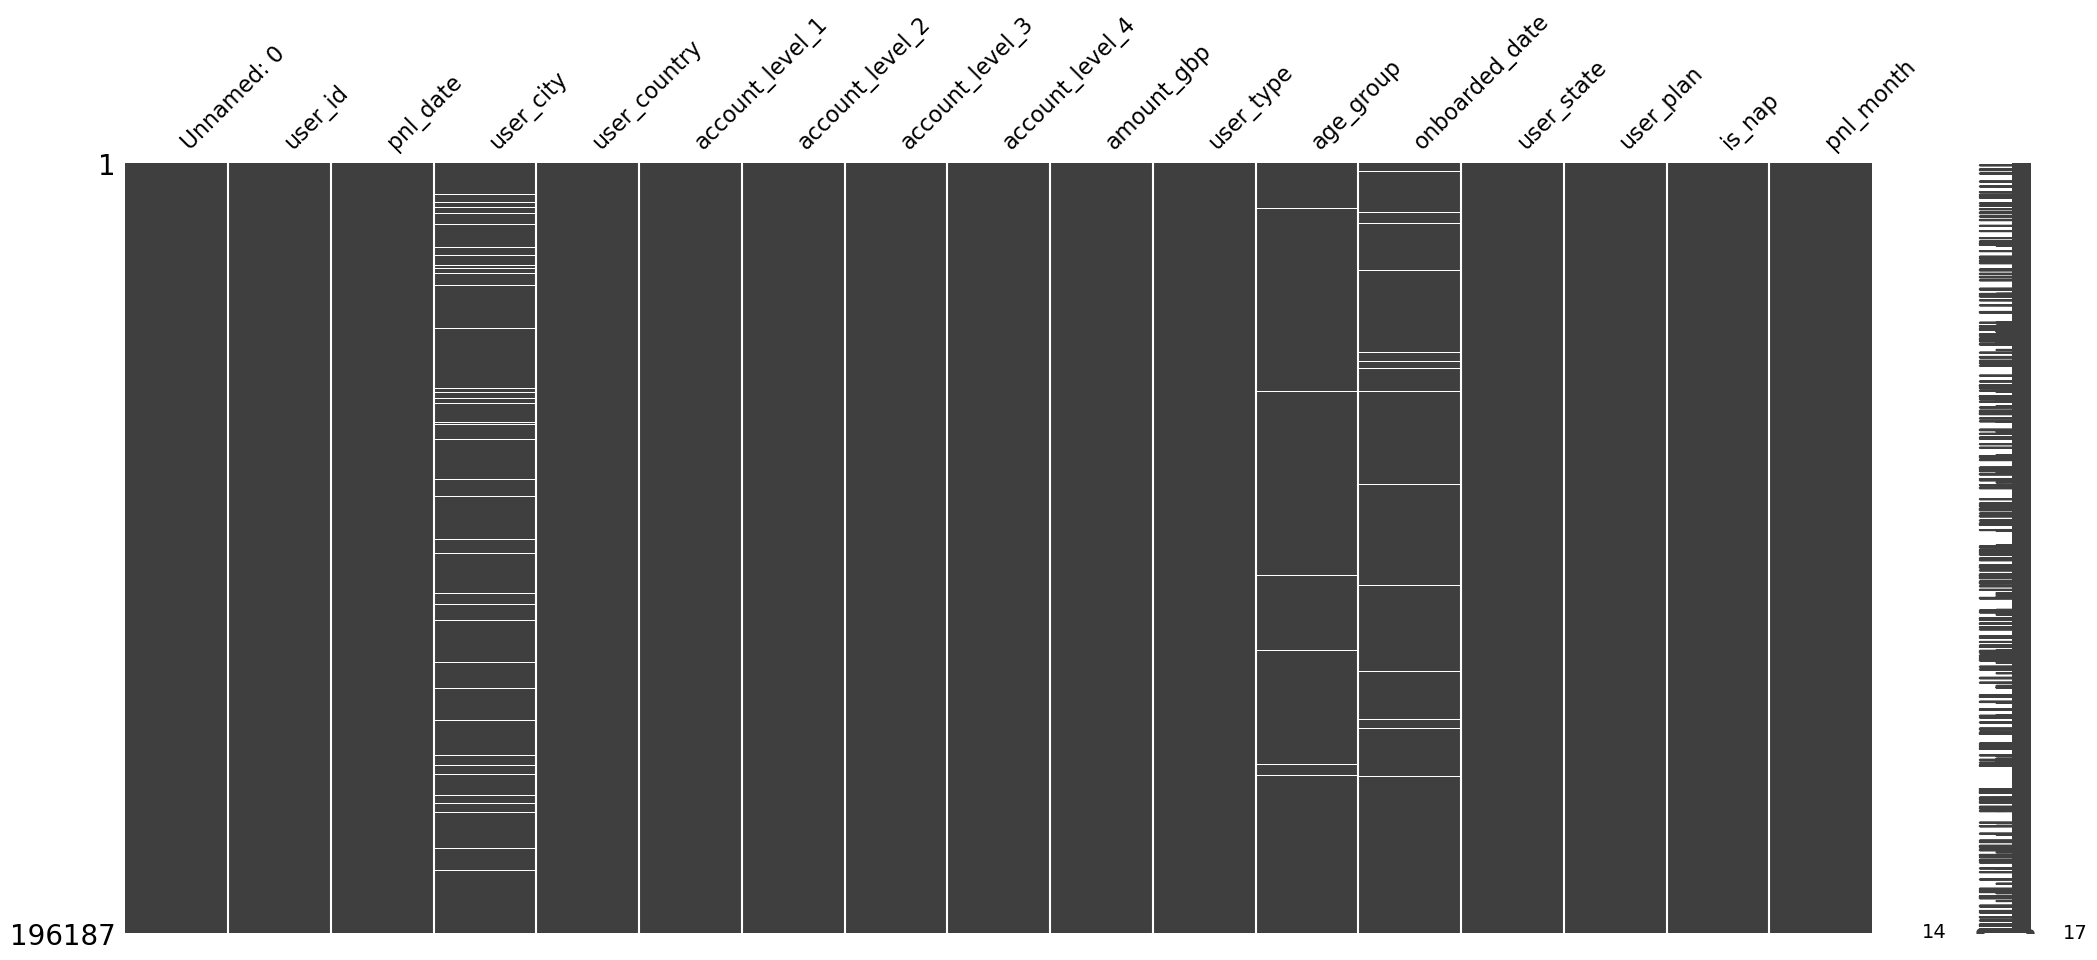

In [6]:
# Display missingness matrix to identify patterns in missingness
missingness_matrix = msno.matrix(data)
missingness_matrix.get_figure().savefig('figures/missingness_matrix.png')

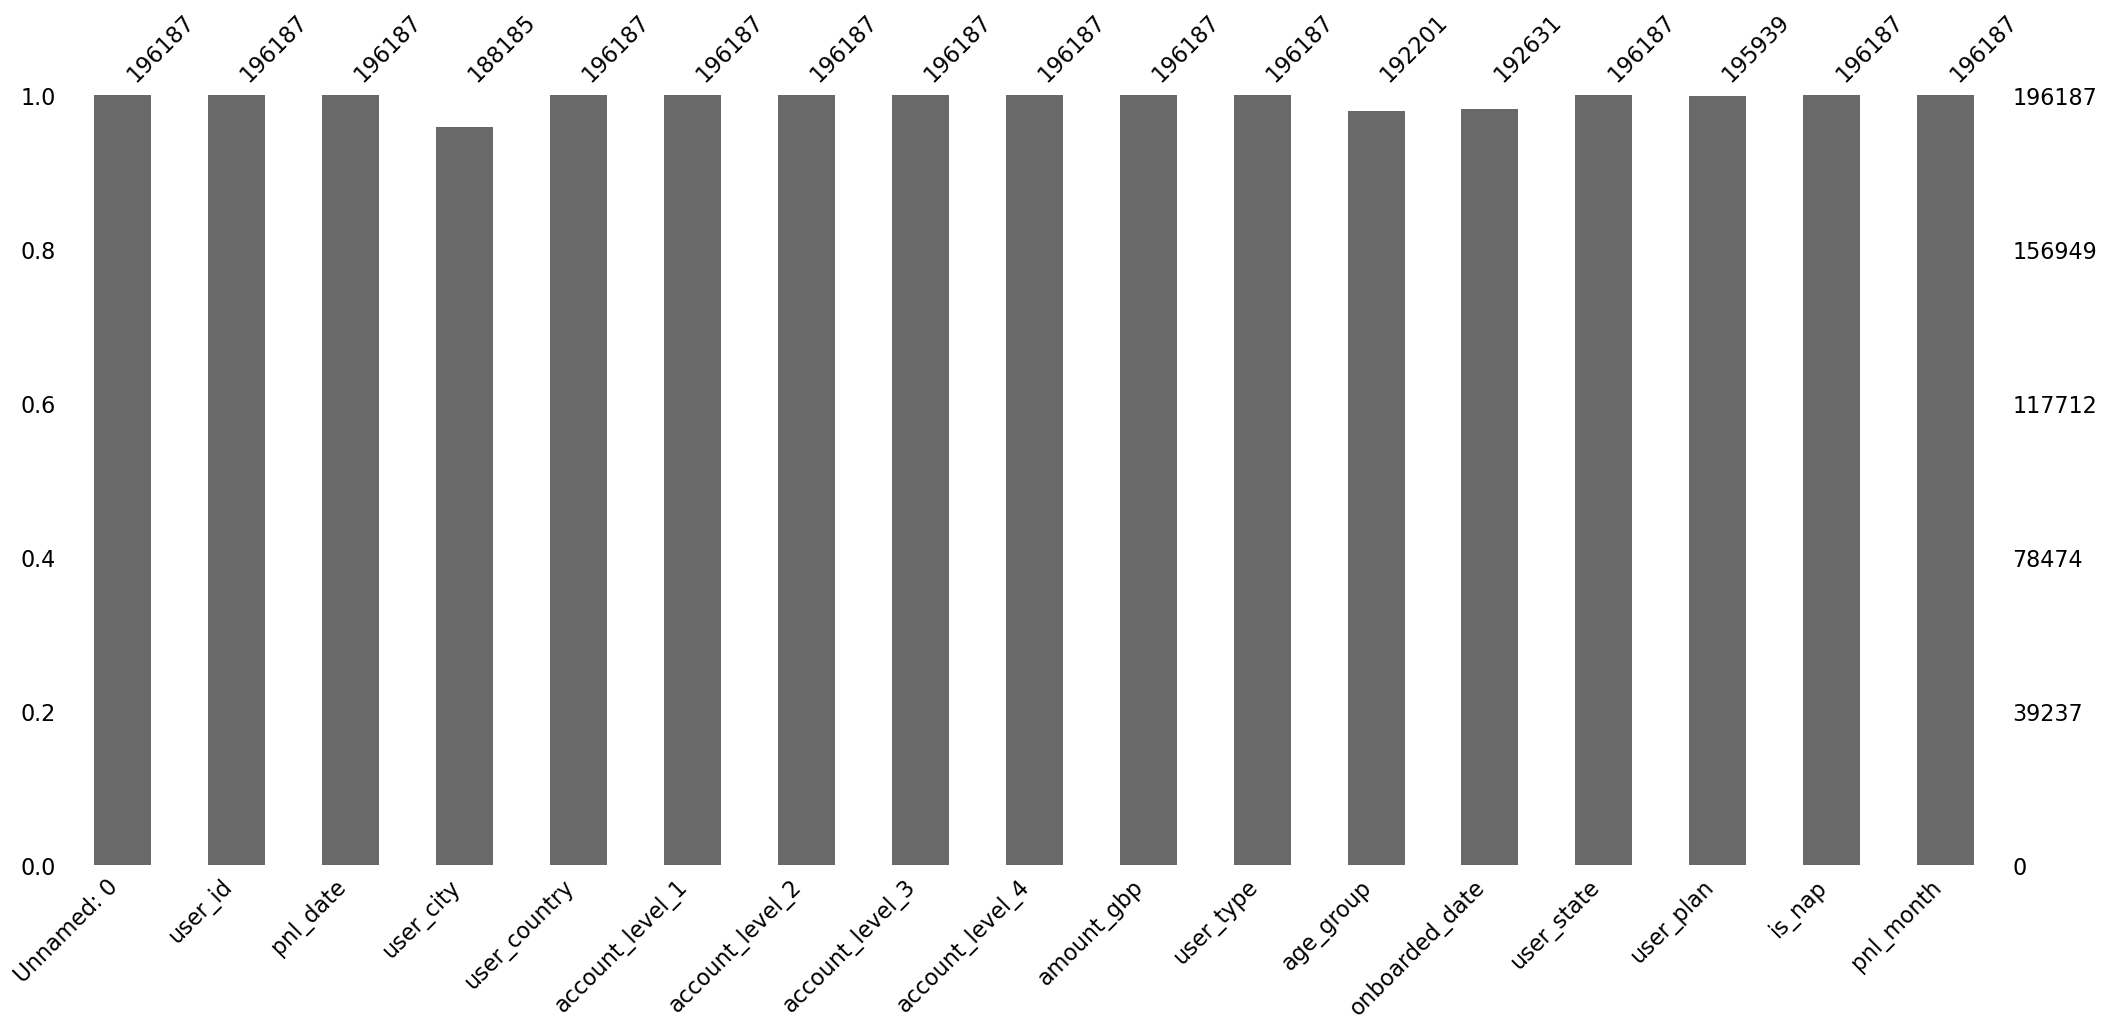

In [7]:
missingness_bar = msno.bar(data)
missingness_bar.get_figure().savefig('figures/missingness_bar.png')

# Preprocessing

In [8]:
# Rename row_id column
data.rename(columns={'Unnamed: 0':'row_id'}, inplace=True)

In [9]:
# Replace 'Fair Usage Fee' with 'Fair Usage Fees' in account_level_4
data.loc[(data['account_level_4']=='Fair Usage Fee'),['account_level_4']] = 'Fair Usage Fees'

In [13]:
# Add a column identifying the 3 30 day periods
start_date = data.pnl_date.min()
data['period'] = np.where(
    (data.pnl_date - start_date).dt.days <=30,
    1,
    np.where(
        (data.pnl_date - start_date).dt.days <=60,
        2,
        3
    )
)

# Export

In [14]:
# Export table to sqlite database
rows_overwritten = data.to_sql(
    'user_monthly_gp',
    conn,
    if_exists='replace'  
)
print(f"Table user_monthly_gp successfully overwritten with {str(rows_overwritten)} rows.")

Table user_monthly_gp successfully overwritten with 196187 rows.


# Postamble

In [15]:
conn.close()